In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RESULTS_DIR = Path('results')
GRAPHS_DIR = Path('graphs')
GRAPHS_DIR.mkdir(exist_ok=True)

In [5]:
df = pd.read_csv(RESULTS_DIR / 'ejercicio4_pi_omp.csv')
df

,esquema,threads,tiempo_s,speedup,eficiencia_pct,pi_estimado
0,reduction,1,0.024494,0.8821,88.21,3.141593
1,reduction,2,0.012149,1.7783,88.91,3.141593
2,reduction,4,0.010369,2.0835,52.09,3.141593
3,reduction,8,0.006271,3.4450,43.06,3.141593
4,reduction,16,0.007932,2.7238,17.02,3.141593
5,critical_parcial,1,0.027308,0.7912,79.12,3.141593
6,critical_parcial,2,0.013731,1.5734,78.67,3.141593
7,critical_parcial,4,0.006105,3.5390,88.48,3.141593
8,critical_parcial,8,0.006393,3.3794,42.24,3.141593
9,critical_parcial,16,0.008853,2.4404,15.25,3.141593


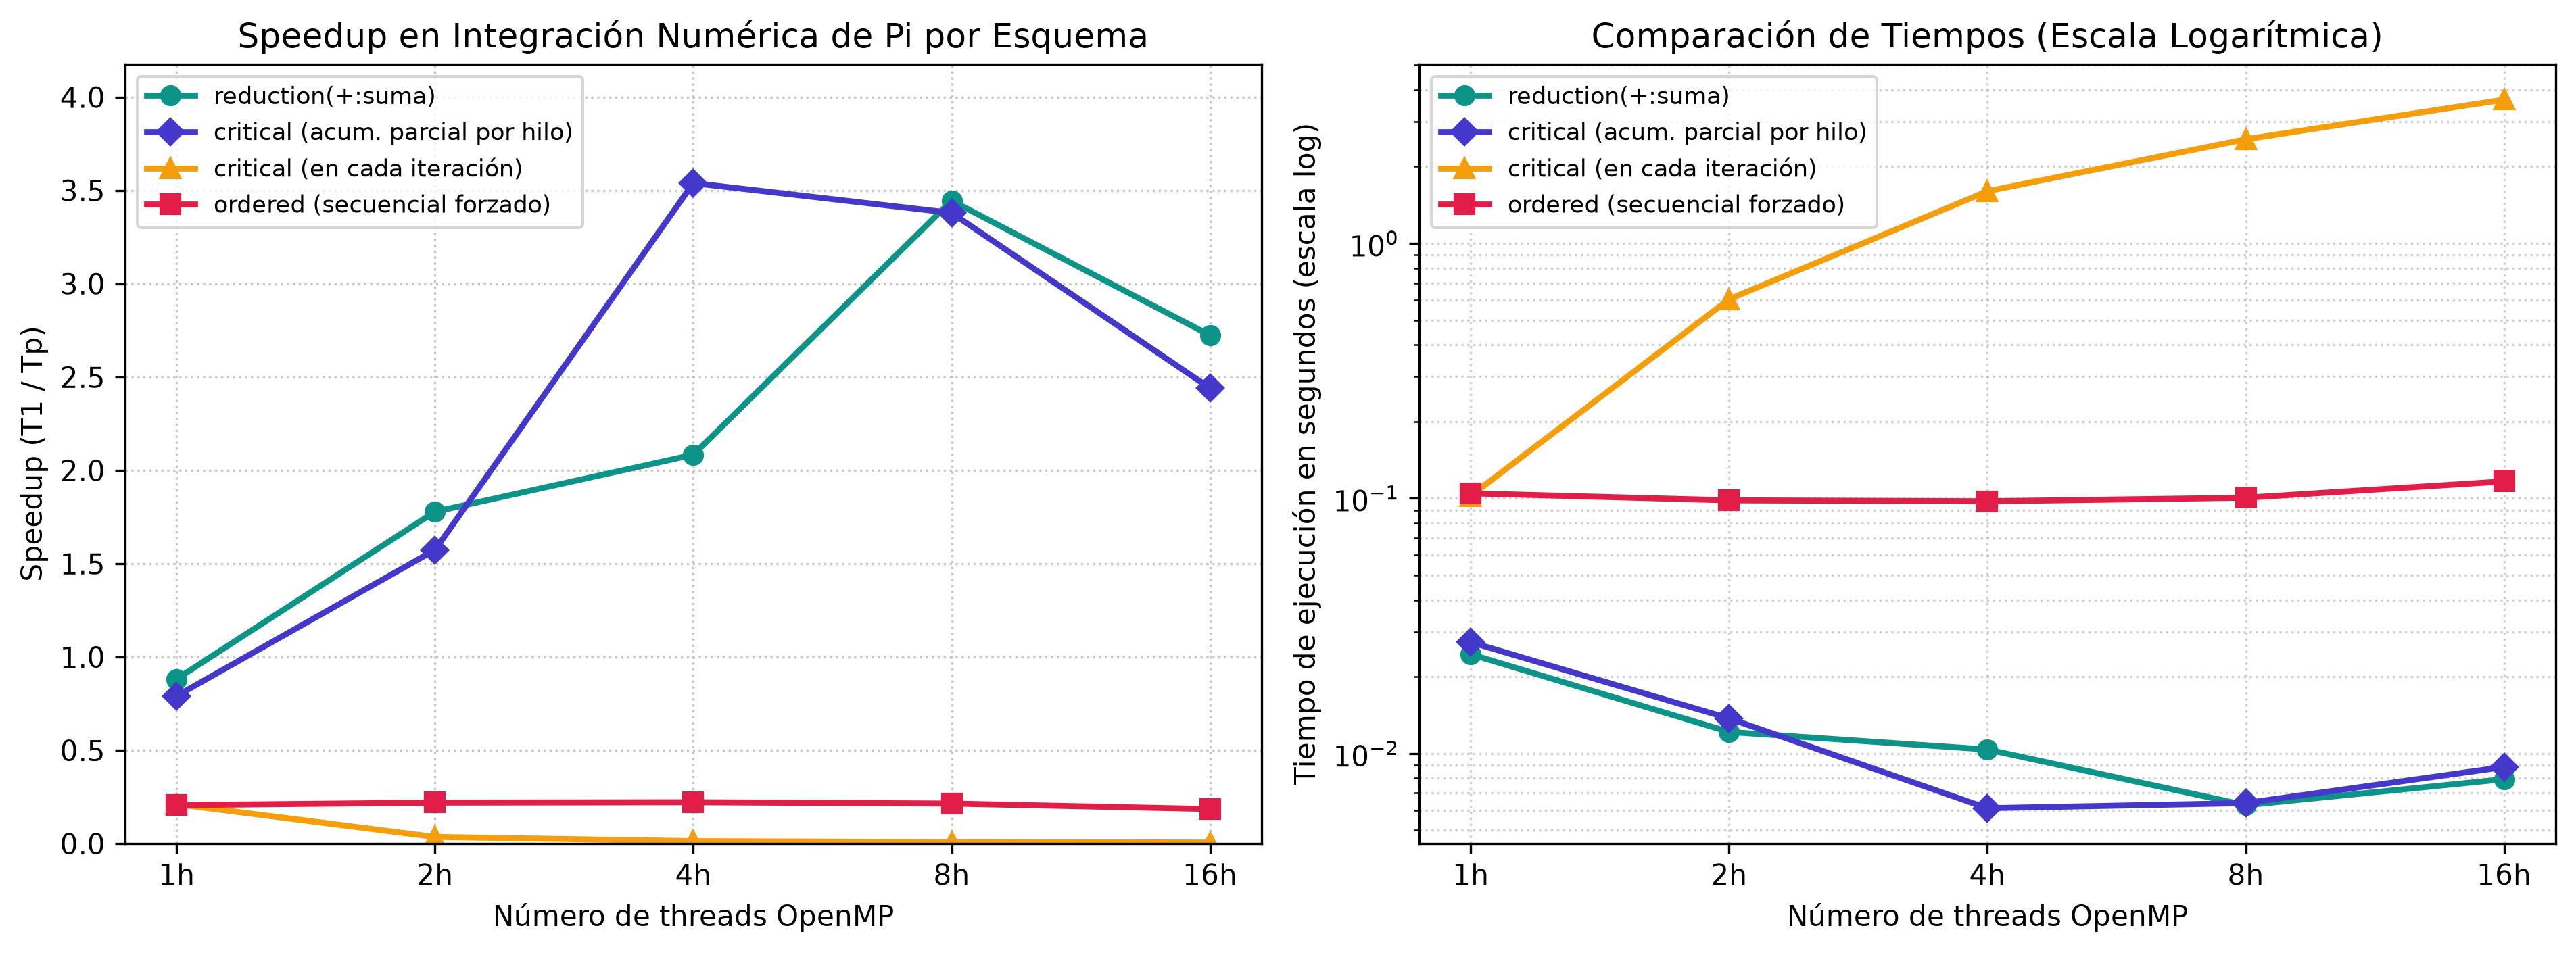

In [6]:
hilos = sorted(df['threads'].unique())
etiquetas_h = [f'{t}h' for t in hilos]
x = np.arange(len(hilos))

esquemas = ['reduction', 'critical_parcial', 'critical_iteracion', 'ordered']
nombres_leg = {
    'reduction': 'reduction(+:suma)',
    'critical_parcial': 'critical (acum. parcial por hilo)',
    'critical_iteracion': 'critical (en cada iteración)',
    'ordered': 'ordered (secuencial forzado)'
}
colores = {
    'reduction': '#0d9488',
    'critical_parcial': '#4338ca',
    'critical_iteracion': '#f59e0b',
    'ordered': '#e11d48'
}
marcadores = {'reduction': 'o', 'critical_parcial': 'D', 'critical_iteracion': '^', 'ordered': 's'}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.8, 4.8), dpi=300)

# Panel izquierdo: Speedup por esquema de sincronización
for esq in esquemas:
    sub = df[df['esquema'] == esq].sort_values('threads')
    sp = sub['speedup'].to_numpy()
    ax1.plot(x, sp, marker=marcadores[esq], markersize=6.5, linewidth=2.1, color=colores[esq], label=nombres_leg[esq])

ax1.set_xticks(x)
ax1.set_xticklabels(etiquetas_h)
ax1.set_ylim(0, max(df['speedup']) * 1.18)
ax1.set_xlabel('Número de threads OpenMP')
ax1.set_ylabel('Speedup (T1 / Tp)')
ax1.set_title('Speedup en Integración Numérica de Pi por Esquema')
ax1.legend(loc='upper left', fontsize=8.5)
ax1.grid(True, linestyle=':', alpha=0.7)

# Panel derecho: Tiempo de ejecución en escala logarítmica
for esq in esquemas:
    sub = df[df['esquema'] == esq].sort_values('threads')
    t_vals = sub['tiempo_s'].to_numpy()
    ax2.plot(x, t_vals, marker=marcadores[esq], markersize=6.5, linewidth=2.1, color=colores[esq], label=nombres_leg[esq])

ax2.set_yscale('log')
ax2.set_xticks(x)
ax2.set_xticklabels(etiquetas_h)
ax2.set_xlabel('Número de threads OpenMP')
ax2.set_ylabel('Tiempo de ejecución en segundos (escala log)')
ax2.set_title('Comparación de Tiempos (Escala Logarítmica)')
ax2.legend(loc='upper left', fontsize=8.5)
ax2.grid(True, which='both', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig(GRAPHS_DIR / 'e4_integracion_pi_omp.png', dpi=300)
plt.show()